# Fuente Única de la Verdad — Entradas a Almacén (SGA)

Este notebook **unifica** dos flujos que provienen de la misma fuente de información (LISA / Zeus):

- La **importación desde el API** del endpoint canónico `entradas_almacen`
  (`POST /galileo/lisa/geninf/isp/sga_entradas`), tal como en `entradas_almacen.ipynb`.
- La **limpieza y ordenamiento** de los datos (fechas → `datetime`, columnas →
  `category`, `numero_pedido` como categórico ordenado), tal como en `recibo.ipynb`.

## ¿Por qué una sola fuente?

`recibo.ipynb` leía un *snapshot* de la BD Zeus (`ds_oc_lineas`, `ds_oc_pedidos`,
`ds_citas`) y su código de limpieza/EDA fue escrito originalmente sobre un dataset de
**entradas** (la variable `entradas_clean_dates_df` y columnas como `USUARIO_GEN`,
`TRABAJADOR`, `FECHA_INICIO`/`FECHA_GEN` siguen comentadas allí). Ambos flujos comparten
las mismas llaves de negocio:

| Concepto | entradas (SGA, API) | recibo `lineas` | recibo `pedidos` | recibo `citas` |
|---|---|---|---|---|
| Pedido | `numero_pedido` | `numero_pedido` | `numero_pedido` | `numero_pedido` |
| Serie | `serie_numeracion` | `serie_numeracion` | `serie_numeracion` | `serie_numeracion` |
| Org. compras | `organizacion_compras` | `organizacion_compras` | `organizacion_compras` | — |
| Proveedor | `proveedor` | — | `codigo_proveedor` | `d_codigo_proveedor` |
| Almacén | `almacen` | — | `codigo_almacen` | — |
| Tipo pedido | `tipo_pedido_com` | — | `tipo_pedido` | — |

En lugar de depender del *snapshot* de la BD, este notebook toma los datos **frescos del
API** y les aplica la misma limpieza. Esa es la única fuente de la verdad.

**Requisitos**

- Token en `LISA_TOKEN` (`.env` o variable de entorno).
- `uv pip install -r requirements.txt`.

**Convenciones LISA**: `fecha_gen` en `dd/mm/aaaa`; "todos los registros" → `regs=-1` (**nunca** `pag=-1`).

In [1]:
import os

import numpy as np
import pandas as pd

# Visualización + estadística para la sección de EDA (estilo recibo.ipynb).
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from lisa_client import LisaClient, LisaAPIError

# El token se lee de LISA_TOKEN (.env o variable de entorno) dentro de LisaClient.
assert os.getenv("LISA_TOKEN"), (
    "Falta LISA_TOKEN. Expórtalo o ponlo en un .env en la raíz del proyecto."
)

## Parámetros de la consulta

Ajusta `FECHA_GEN` (obligatorio) y, opcionalmente, `ALMACEN` (vacío = todos los almacenes).

In [2]:
FECHA_GEN = "01/06/2026"  # dd/mm/aaaa
ALMACEN = "5460D"          # "" = todos los almacenes
REGS = -1                  # -1 = todos los registros (default canónico)

## 1. Importación desde el API

In [3]:
client = LisaClient()

try:
    respuesta = client.entradas_almacen(
        fecha_gen=FECHA_GEN,
        almacen=ALMACEN,
        regs=REGS,
    )
except LisaAPIError as e:
    raise SystemExit(f"Error en la API LISA: {e}")

rowstat = respuesta.get("registros", {}).get("rowstat", {})
print("rowstat:", rowstat)

17:38:12 [INFO] POST /galileo/lisa/geninf/isp/sga_entradas | body: {'p_fecha_gen': '01/06/2026', 'p_almacen': '5460D'}


rowstat: {'numero_registros': 483}


In [4]:
# Los registros de negocio vienen en registros.reg. Cuando hay un solo registro la
# API devuelve un dict en lugar de una lista, así que lo normalizamos antes de pandas.
registros = respuesta.get("registros", {})
reg = registros.get("reg") or []
if isinstance(reg, dict):  # un solo registro -> lista de uno
    reg = [reg]

df = pd.json_normalize(reg)
print(f"Filas: {len(df)}  |  Columnas: {df.shape[1]}")
df.head()

Filas: 483  |  Columnas: 34


,numero_tarea,fecha_gen,usuario_gen,maquina_gen,fecha_inicio,fecha_fin,prioridad,maquina,usuario,status_tarea,...,zona_almacen,situacion,zona_trabajo,tipo_entrada,tipo_recepcion_paletizada,entrada_sga,tratamiento_especial,reserva_ped_vtas,trabajador,numero_factura_fiscal
0,13920,01/06/2026,GAPEAR,XO,01/06/2026,01/06/2026,50,XO,GAPEAR,C,...,02,CAL,RC,ES,D,S,N,S,GAPEAR,NaN
1,14028,04/06/2026,SOCALEG,RB,04/06/2026,04/06/2026,50,RB,SOCALEG,C,...,02,CAL,RC,ES,D,S,N,S,SOCALEG,NaN
2,14033,04/06/2026,SELANDE,RD,04/06/2026,04/06/2026,50,RD,SELANDE,C,...,02,CAL,RC,ES,D,S,N,S,SELANDE,NaN
3,14041,04/06/2026,CAVAVA,RE,04/06/2026,04/06/2026,50,RE,CAVAVA,C,...,02,CAL,RC,ES,D,S,N,S,CAVAVA,NaN
4,14067,05/06/2026,ENSAPAOD,XO,05/06/2026,05/06/2026,50,XO,ENSAPAOD,C,...,02,CAL,RC,ES,D,S,N,S,ENSAPAOD,NaN


## 2. Limpieza — fechas a `datetime`

Igual que en `recibo.ipynb`, convertimos las columnas de fecha (`dd/mm/aaaa`, en texto) a
`datetime64` con `pd.to_datetime(..., format="mixed", dayfirst=True)`. Solo se procesan las
columnas de fecha presentes en la respuesta del API (`errors="coerce"` deja `NaT` ante
cualquier valor no parseable).

In [5]:
df_limpio = df.copy()

# Columnas de fecha del endpoint sga_entradas (todas en dd/mm/aaaa).
COLS_FECHA = ["fecha_gen", "fecha_inicio", "fecha_fin", "fecha_doc_externo", "fecha"]
cols_fecha = [c for c in COLS_FECHA if c in df_limpio.columns]

for col in cols_fecha:
    df_limpio[col] = pd.to_datetime(
        df_limpio[col], format="mixed", dayfirst=True, errors="coerce"
    )

print(df_limpio[cols_fecha].dtypes)

fecha_gen            datetime64[us]
fecha_inicio         datetime64[us]
fecha_fin            datetime64[us]
fecha_doc_externo    datetime64[us]
fecha                datetime64[us]
dtype: object


## 3. Ordenamiento — categóricos

Replicamos el criterio de `recibo.ipynb`:

- `numero_pedido` → categórico **ordenado** (escala ordinal con holgura `0 … max*10`).
- El resto de columnas de baja cardinalidad (`object`/`int`/`float`) → `category`.
- Se conservan como numéricos los **identificadores únicos** (`numero_tarea`,
  `numero_doc_interno`), que son IDs, no categorías.

In [6]:
# numero_pedido como categórico ordenado (mismo criterio que recibo.ipynb).
n = int(df_limpio["numero_pedido"].max()) * 10
categorias = np.arange(0, n + 1)
df_limpio["numero_pedido"] = pd.Categorical(
    df_limpio["numero_pedido"], categories=categorias, ordered=True
)

# Resto de columnas object/str/int/float -> category, excepto IDs únicos y el ya-ordinal.
# (Se incluye "str" explícitamente para que el casteo siga funcionando en pandas 3.)
cols_convertir = df_limpio.select_dtypes(include=["float64", "object", "str", "int64"]).columns
cols_excluir = ["numero_tarea", "numero_doc_interno", "numero_pedido"]

for col in cols_convertir:
    if col not in cols_excluir:
        df_limpio[col] = df_limpio[col].astype("category")

print(f"Categóricas: {len(df_limpio.select_dtypes(include='category').columns)}")
print(f"Fechas:      {len(df_limpio.select_dtypes(include='datetime').columns)}")

Categóricas: 27
Fechas:      5


In [7]:
df_limpio.info()

<class 'pandas.DataFrame'>
RangeIndex: 483 entries, 0 to 482
Data columns (total 34 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   numero_tarea               483 non-null    int64         
 1   fecha_gen                  483 non-null    datetime64[us]
 2   usuario_gen                483 non-null    category      
 3   maquina_gen                483 non-null    category      
 4   fecha_inicio               483 non-null    datetime64[us]
 5   fecha_fin                  482 non-null    datetime64[us]
 6   prioridad                  483 non-null    category      
 7   maquina                    483 non-null    category      
 8   usuario                    483 non-null    category      
 9   status_tarea               483 non-null    category      
 10  tipo_movimiento            483 non-null    category      
 11  numero_doc_interno         483 non-null    str           
 12  proveedor          

## 4. Persistir el dataset limpio (opcional)

In [8]:
salida = f"fuente_unica_entradas_{FECHA_GEN.replace('/', '-')}_{ALMACEN or 'todos'}.csv"
df_limpio.to_csv(salida, index=False, encoding="utf-8")
print(f"Guardado en {salida}")

Guardado en fuente_unica_entradas_01-06-2026_5460D.csv


## 5. EDA / correlaciones (adaptado de `recibo.ipynb`)

`recibo.ipynb` dejó comentado un análisis de asociación entre variables categóricas
(Chi-cuadrada + V de Cramér) y gráficos de frecuencias, escrito originalmente para un
dataset de entradas. Aquí lo reactivamos **adaptado a las columnas que sí existen** en la
respuesta actual del endpoint `sga_entradas` (no incluye `contador`, `ubicacion_*`,
`cant_pres`, `unidades1`, que pertenecían a una exportación más amplia).

In [9]:
# Estilo de gráficos (modo oscuro, igual que recibo.ipynb).
plt.style.use("dark_background")
plt.rcParams.update({
    "axes.edgecolor": "white",
    "axes.labelcolor": "white",
    "text.color": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "grid.color": "lightgray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.5,
    "figure.figsize": (8, 6),
})

In [10]:
def asociacion_categorica(df, col_a, col_b):
    """Chi-cuadrada + V de Cramér entre dos columnas categóricas (estilo recibo.ipynb).

    p < 0.05 -> existe relación estadísticamente significativa.
    V de Cramér ~0 = sin asociación, ~1 = asociación total.
    """
    tabla = pd.crosstab(df[col_a], df[col_b])
    chi2, p_val, dof, _ = stats.chi2_contingency(tabla)
    n = tabla.sum().sum()
    min_dim = min(tabla.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else np.nan
    print(f"{col_a:14s} vs {col_b:14s} | p={p_val:.3e} | V de Cramér={cramers_v:.3f}")
    return p_val, cramers_v


# Pares heredados del análisis comentado en recibo.ipynb, adaptados a columnas existentes.
pares = [
    ("usuario_gen", "usuario"),
    ("trabajador", "usuario"),
    ("fecha_inicio", "fecha_gen"),
    ("maquina_gen", "maquina"),
    ("usuario_gen", "maquina_gen"),
]
for a, b in pares:
    if a in df_limpio.columns and b in df_limpio.columns:
        asociacion_categorica(df_limpio, a, b)

usuario_gen    vs usuario        | p=0.000e+00 | V de Cramér=1.000
trabajador     vs usuario        | p=0.000e+00 | V de Cramér=1.000
fecha_inicio   vs fecha_gen      | p=0.000e+00 | V de Cramér=1.000
maquina_gen    vs maquina        | p=0.000e+00 | V de Cramér=1.000
usuario_gen    vs maquina_gen    | p=0.000e+00 | V de Cramér=0.954


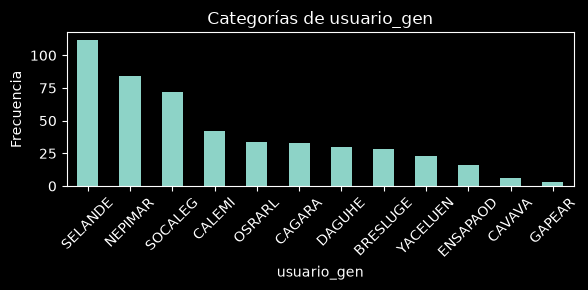

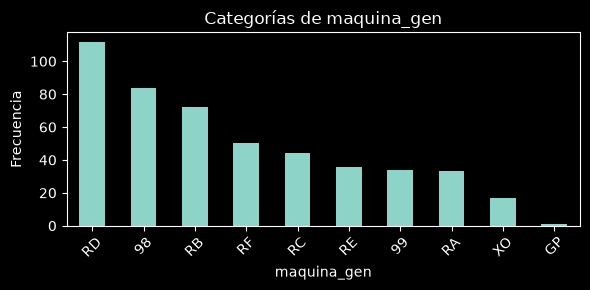

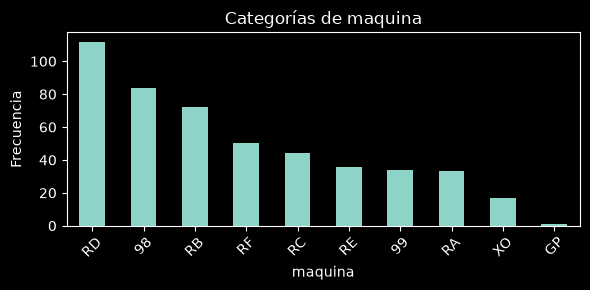

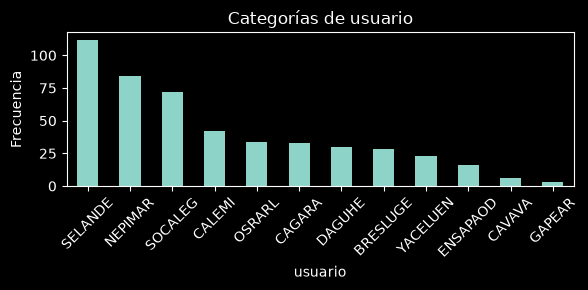

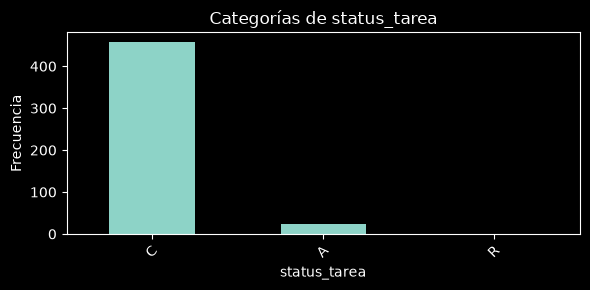

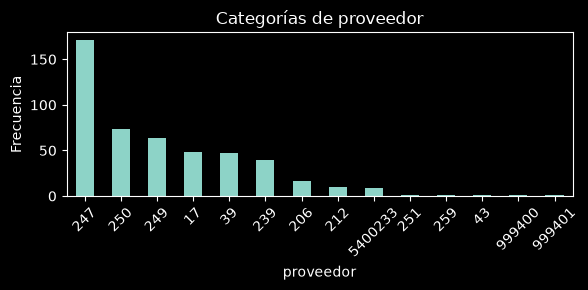

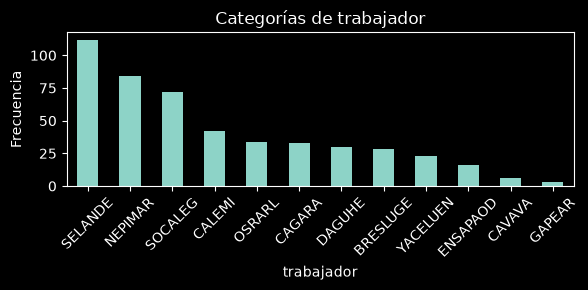

In [11]:
# Frecuencias de las categóricas de baja cardinalidad (estilo recibo.ipynb).
cat_cols = [
    c for c in df_limpio.select_dtypes(include="category").columns
    if 1 < df_limpio[c].nunique() <= 25 and c != "numero_pedido"
]

for col in cat_cols:
    counts = df_limpio[col].value_counts()
    fig, ax = plt.subplots(figsize=(6, 3))
    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"Categorías de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()